
# Imam Abdulrahman Bin Faisal University
## ARTI 502 – Deep Learning
### Assignment 2: Training-Testing CNN with CIFAR Dataset using Pytorch

**Instructor:** Dr. Moatasem Alsmadi

**Group Number:** 4

**Group Members:**
1. Renad Salem Alqahtani – 2230004724
2. Jana Omar Alghamdi – 2230002367
3. Jood Yasser Alarfaj – 2230002692
4. Leen Mansour Alqahtani – 2230006599
5. Ghala Nassar Al-muriki – 2230006331
6. Wajd Mohammed Alqahtani – 2230005130


## Task 1: Getting the CIFAR Dataset

In [1]:
import torch
import torchvision
import torchvision.transforms as transforms
import os

DATA_PATH = './cifar_data'
os.makedirs(DATA_PATH, exist_ok=True)

transform = transforms.Compose([
    transforms.ToTensor()
])

trainset = torchvision.datasets.CIFAR10(
    root=DATA_PATH,
    train=True,
    download=True,
    transform=transform
)

testset = torchvision.datasets.CIFAR10(
    root=DATA_PATH,
    train=False,
    download=True,
    transform=transform
)

print("CIFAR-10 Dataset loaded successfully!")
print("Total training samples:", len(trainset))
print("Total testing samples:", len(testset))


100%|██████████| 170M/170M [28:14<00:00, 101kB/s] 


CIFAR-10 Dataset loaded successfully!
Total training samples: 50000
Total testing samples: 10000


##Task 2: Defining the Network


**Network Architecture Definition**

In [2]:
import torch.nn as nn
import torch.nn.functional as F

class CNN(nn.Module):
    def __init__(self):
        super(CNN, self).__init__()
        # Conv block 1: in_channels=3 (RGB), out_channels=32, kernel_size=3, stride=1, padding=1
        self.conv1 = nn.Conv2d(in_channels=3, out_channels=32, kernel_size=3, stride=1, padding=1)
        # Conv block 2: in_channels=32, out_channels=64, kernel_size=3, stride=1, padding=1
        self.conv2 = nn.Conv2d(in_channels=32, out_channels=64, kernel_size=3, stride=1, padding=1)

        # Maxpooling layer: kernel_size=2, stride=2
        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)

        # Fully connected layers (Classifier)
        # Input image: 32x32 -> After pool 1: 16x16 -> After pool 2: 8x8 -> 64 channels * 8 * 8
        self.fc1 = nn.Linear(64 * 8 * 8, 128)
        self.fc2 = nn.Linear(128, 10)  # 10 output classes for CIFAR-10

    def forward(self, x):
        # Feature extraction using convolution, activation, and maxpooling
        x = self.pool(F.relu(self.conv1(x)))
        x = self.pool(F.relu(self.conv2(x)))

        # Flatten feature maps before feeding into the classifier
        x = x.view(x.size(0), -1)

        # Classification head
        x = F.relu(self.fc1(x))
        x = self.fc2(x)
        return x

# Instantiate the model
model = CNN()
print(model)

CNN(
  (conv1): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (fc1): Linear(in_features=4096, out_features=128, bias=True)
  (fc2): Linear(in_features=128, out_features=10, bias=True)
)


**Base Training & Testing Functions**

In [3]:

import torch
import torch.nn as nn
import torch.optim as optim

# Training function
def train(model, trainloader, criterion, optimizer, device):
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in trainloader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)
        _, predicted = torch.max(outputs, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    epoch_loss = running_loss / total
    epoch_accuracy = 100 * correct / total

    return epoch_loss, epoch_accuracy


# Testing function
def test(model, testloader, criterion, device):
    model.eval()
    running_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in testloader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            running_loss += loss.item() * images.size(0)
            _, predicted = torch.max(outputs, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    test_loss = running_loss / total
    test_accuracy = 100 * correct / total

    return test_loss, test_accuracy


##Task 3: Loading Data

Part 1: Find the images tensor size

In [4]:
from torch.utils.data import DataLoader

# Load a batch of 8 images
trainloader = DataLoader(trainset, batch_size=8, shuffle=True)

# Get the images and labels
images, labels = next(iter(trainloader))

# Print their sizes
print("Images tensor size:", images.shape)
print("Labels tensor size:", labels.shape)


Images tensor size: torch.Size([8, 3, 32, 32])
Labels tensor size: torch.Size([8])


Part 2: Visualize images using Matplotlib

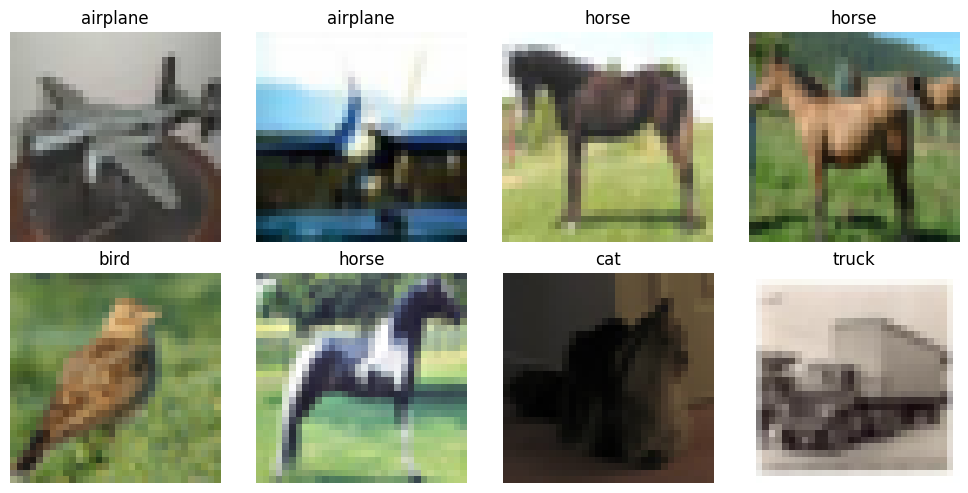

In [5]:
import matplotlib.pyplot as plt

# Display the images
fig, axes = plt.subplots(2, 4, figsize=(10, 5))

for i, ax in enumerate(axes.flat):
    image = images[i].permute(1, 2, 0)
    ax.imshow(image)
    ax.set_title(trainset.classes[labels[i].item()])
    ax.axis('off')

plt.tight_layout()
plt.show()


##Task 4: Dataset Augmentation

##Task 5: Training Function and Tuning hyperparameters